# 13. Kết quả và phân tích
Nhánh GitHub: `13-ket-qua`

Gộp kết quả các notebook E1–E9 (`runs_E*.csv`) và phân tích. Chạy sau khi các thí nghiệm đã xong.

In [1]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup(gpu=False)

Mounted at /content/drive
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [2]:
meta, X, X_DEV, y, folds = load_data()

  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cpu


### 8.1. Bảng so sánh Accuracy và Macro-F1 (trung bình ± độ lệch chuẩn qua các fold)

,Mô hình,Mel bins,SpecAugment,Accuracy (%),Macro-F1 (%),Learning rate,Số tham số,Thời gian/lượt (s)
exp,,,,,,,,
E1,CNN,64,Tắt,80.80 ± 2.05,80.06 ± 2.28,0.0003,"1,185,490",94
E2,CNN,128,Tắt,84.55 ± 2.09,83.95 ± 2.23,0.001,"1,185,490",162
E3,CNN,64,Bật,83.15 ± 2.74,82.45 ± 3.43,0.001,"1,185,490",89
E4,CNN,128,Bật,82.90 ± 2.21,82.34 ± 2.36,0.001,"1,185,490",181
E5,CRNN,64,Tắt,75.65 ± 2.14,74.59 ± 2.47,0.001,"2,071,762",103
E6,CRNN,128,Tắt,77.25 ± 1.98,76.16 ± 2.48,0.0003,"2,858,194",200
E7,CRNN,64,Bật,79.45 ± 1.65,78.68 ± 1.99,0.0003,"2,071,762",104
E8,CRNN,128,Bật,78.00 ± 2.83,76.92 ± 3.19,0.001,"2,858,194",202
E9,PANNs CNN14 (pretrained),64,Bật,93.80 ± 2.35,93.57 ± 2.52,0.0001 / 0.001 (backbone / head),"79,776,242",253


Số fold đã chạy: 5


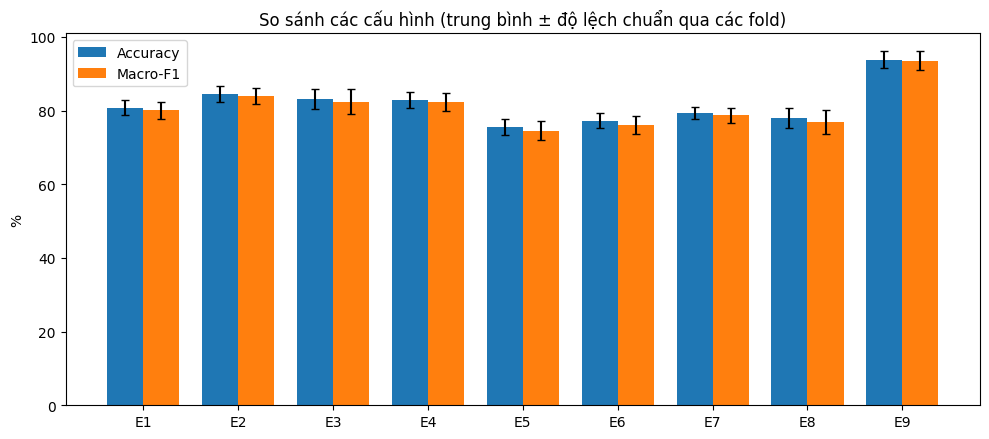

In [3]:
runs, rob = load_results()
FOLDS_DONE = sorted(runs["fold"].unique())
ordered = [e for e in EXPERIMENTS if e in runs["exp"].unique()]

summary = runs.groupby("exp").agg(
    acc_mean=("acc", "mean"), acc_std=("acc", "std"),
    f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
    params=("params", "first"), lr=("lr", "first"), time_mean=("train_time", "mean"),
).reindex(ordered).fillna(0.0)

table = pd.DataFrame({
    "Mô hình": [{"cnn": "CNN", "crnn": "CRNN", "panns": "PANNs CNN14 (pretrained)"}[EXPERIMENTS[e]["model"]]
                for e in summary.index],
    "Mel bins": [EXPERIMENTS[e]["n_mels"] for e in summary.index],
    "SpecAugment": ["Bật" if EXPERIMENTS[e]["specaug"] else "Tắt" for e in summary.index],
    "Accuracy (%)": [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(summary.acc_mean, summary.acc_std)],
    "Macro-F1 (%)": [f"{m * 100:.2f} ± {s * 100:.2f}" for m, s in zip(summary.f1_mean, summary.f1_std)],
    "Learning rate": [f"{PANNS_CFG['LR_BACKBONE']:g} / {PANNS_CFG['LR_HEAD']:g} (backbone / head)" if e == "E9" else f"{v:g}"
                      for e, v in zip(summary.index, summary.lr)],
    "Số tham số": [f"{int(p):,}" for p in summary.params],
    "Thời gian/lượt (s)": [f"{t:.0f}" for t in summary.time_mean],
}, index=summary.index)
display(table)
table.to_csv(RESULT_DIR / "summary_table.csv")
print("Số fold đã chạy:", len(FOLDS_DONE))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(summary))
w = 0.38
ax.bar(x - w / 2, summary.acc_mean * 100, w, yerr=summary.acc_std * 100, capsize=3, label="Accuracy")
ax.bar(x + w / 2, summary.f1_mean * 100, w, yerr=summary.f1_std * 100, capsize=3, label="Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("%")
ax.set_title("So sánh các cấu hình (trung bình ± độ lệch chuẩn qua các fold)")
ax.legend()
plt.tight_layout()
plt.show()

### 8.2. Kết quả từng fold

In [4]:
for title, col, fname in (("Accuracy (%)", "acc", "per_fold_accuracy.csv"),
                          ("Macro-F1 (%)", "macro_f1", "per_fold_macro_f1.csv")):
    base = runs.pivot(index="fold", columns="exp", values=col)[ordered]
    table_fold = base * 100
    table_fold.loc["Trung bình"] = base.mean() * 100
    table_fold.loc["Độ lệch chuẩn"] = base.std() * 100
    table_fold.index = [f"Fold {i}" if isinstance(i, (int, np.integer)) else i
                        for i in table_fold.index]
    table_fold.to_csv(RESULT_DIR / fname)
    print(title + " trên từng fold test:")
    display(table_fold.round(2))

Accuracy (%) trên từng fold test:


exp,E1,E2,E3,E4,E5,E6,E7,E8,E9
Fold 1,81.25,82.00,82.25,83.25,75.00,75.75,77.75,76.00,94.00
Fold 2,83.75,83.25,84.50,83.25,77.50,79.00,80.75,80.00,97.50
Fold 3,81.25,85.25,84.75,85.25,74.25,75.50,79.25,NaN,93.25
Fold 4,79.25,87.50,85.50,83.50,78.25,79.75,81.50,NaN,93.25
Fold 5,78.50,84.75,78.75,79.25,73.25,76.25,78.00,NaN,91.00
Trung bình,80.80,84.55,83.15,82.90,75.65,77.25,79.45,78.00,93.80
Độ lệch chuẩn,2.05,2.09,2.74,2.21,2.14,1.98,1.65,2.83,2.35


Macro-F1 (%) trên từng fold test:


exp,E1,E2,E3,E4,E5,E6,E7,E8,E9
Fold 1,80.56,81.29,81.24,82.47,73.78,74.13,76.44,74.66,93.63
Fold 2,83.09,82.64,84.26,82.80,76.72,78.16,80.15,79.17,97.50
Fold 3,80.80,85.12,84.31,84.72,73.24,74.71,78.91,NaN,93.12
Fold 4,78.90,87.06,85.46,83.29,77.56,79.48,81.00,NaN,93.15
Fold 5,76.97,83.62,76.99,78.41,71.67,74.33,76.89,NaN,90.48
Trung bình,80.06,83.95,82.45,82.34,74.59,76.16,78.68,76.92,93.57
Độ lệch chuẩn,2.28,2.23,3.43,2.36,2.47,2.48,1.99,3.19,2.52


### 8.3. Đường học (learning curves)

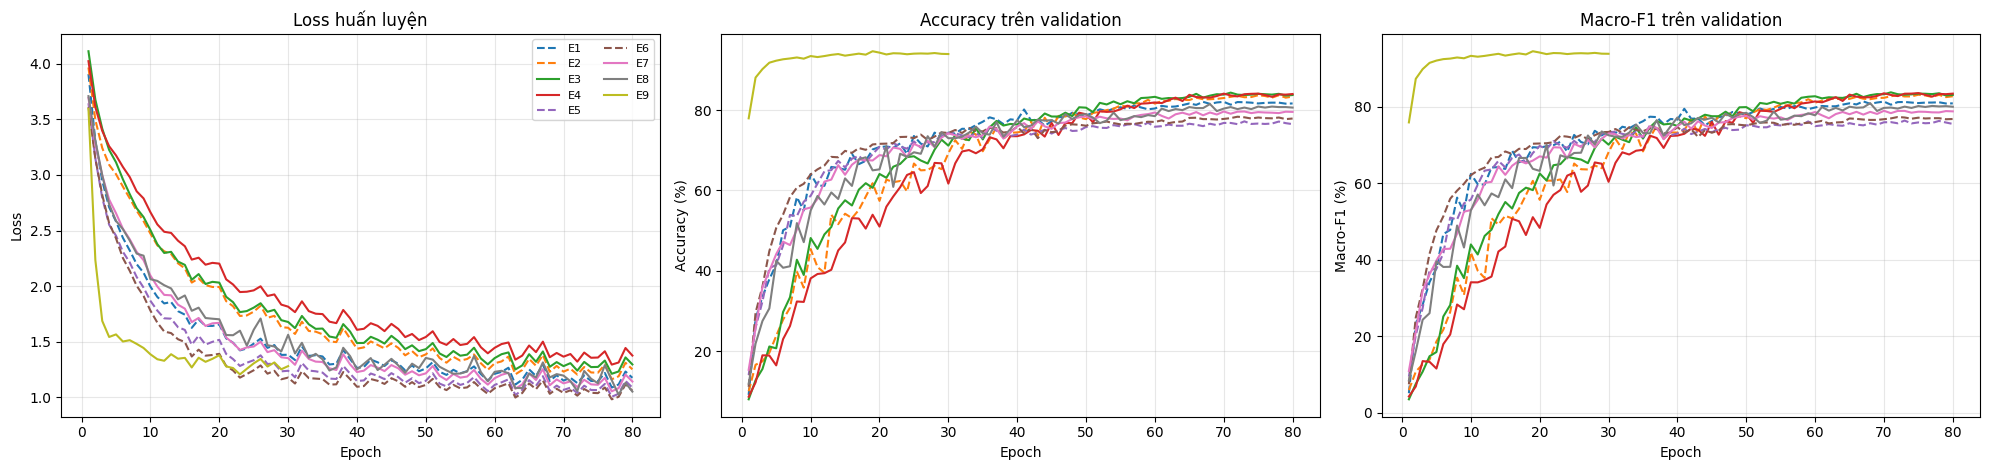

,Epoch tốt nhất (trung bình),Nhỏ nhất,Lớn nhất
exp,,,
E1,64.8,36,76
E2,70.6,57,78
E3,68.6,62,72
E4,73.2,65,79
E5,59.0,47,73
E6,68.2,66,72
E7,69.2,64,75
E8,72.5,68,77
E9,19.0,15,23


In [5]:
frames = []
for e in ordered:
    for f in sorted(runs["fold"].unique()):
        p = RESULT_DIR / f"history_{e}_fold{f}.csv"
        if p.exists():
            h = pd.read_csv(p)
            h["exp"], h["fold"] = e, f
            frames.append(h)

if frames:
    hist = pd.concat(frames, ignore_index=True)
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
    for e in ordered:
        g = hist[hist["exp"] == e].groupby("epoch")[["loss", "val_acc", "val_f1"]].mean()
        if g.empty:
            continue
        style = "-" if EXPERIMENTS[e]["specaug"] else "--"
        axes[0].plot(g.index, g["loss"], style, label=e)
        axes[1].plot(g.index, g["val_acc"] * 100, style, label=e)
        axes[2].plot(g.index, g["val_f1"] * 100, style, label=e)
    for ax, title, ylabel in zip(axes,
                                 ("Loss huấn luyện", "Accuracy trên validation", "Macro-F1 trên validation"),
                                 ("Loss", "Accuracy (%)", "Macro-F1 (%)")):
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Không tìm thấy file lịch sử huấn luyện (history_*.csv) trong thư mục kết quả.")

best_ep = runs.groupby("exp")["best_epoch"].agg(["mean", "min", "max"]).reindex(ordered).round(1)
best_ep.columns = ["Epoch tốt nhất (trung bình)", "Nhỏ nhất", "Lớn nhất"]
display(best_ep)

### 8.4. Trả lời RQ1, RQ2, RQ3

In [6]:
RQ_PAIRS = {
    "RQ1: CRNN so với CNN":        [("E1", "E5"), ("E2", "E6"), ("E3", "E7"), ("E4", "E8")],
    "RQ2: 128 so với 64 Mel bins": [("E1", "E2"), ("E3", "E4"), ("E5", "E6"), ("E7", "E8")],
    "RQ3: bật so với tắt SpecAugment": [("E1", "E3"), ("E2", "E4"), ("E5", "E7"), ("E6", "E8")],
}
piv_f1 = runs.pivot(index="fold", columns="exp", values="macro_f1")
piv_acc = runs.pivot(index="fold", columns="exp", values="acc")

rows = []
for rq, pairs in RQ_PAIRS.items():
    for a, b in pairs:
        if a not in piv_f1.columns or b not in piv_f1.columns:
            continue
        pair_f1 = piv_f1[[a, b]].dropna()
        d_f1 = pair_f1[b] - pair_f1[a]
        d_acc = (piv_acc[b] - piv_acc[a]).dropna()
        p_t = p_w = np.nan
        if len(pair_f1) >= 2:
            p_t = stats.ttest_rel(pair_f1[b], pair_f1[a]).pvalue
            try:
                p_w = stats.wilcoxon(d_f1).pvalue
            except ValueError:
                p_w = np.nan
        rows.append({"Câu hỏi": rq, "So sánh": f"{a} → {b}",
                     "Δ Accuracy (điểm %)": round(d_acc.mean() * 100, 2),
                     "Δ Macro-F1 (điểm %)": round(d_f1.mean() * 100, 2),
                     "p (t-test)": round(p_t, 4) if not np.isnan(p_t) else None,
                     "p (Wilcoxon)": round(p_w, 4) if not np.isnan(p_w) else None})

rq_table = pd.DataFrame(rows)


def holm(p):
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


rq_table["p (t-test, Holm)"] = holm(rq_table["p (t-test)"].astype(float).fillna(1.0).values).round(4)
rq_table["p (Wilcoxon, Holm)"] = holm(rq_table["p (Wilcoxon)"].astype(float).fillna(1.0).values).round(4)
display(rq_table)
print("Holm hiệu chỉnh cho 12 phép so sánh; chỉ nên coi là có ý nghĩa khi p (Holm) < 0,05. "
      "Các fold dùng dữ liệu huấn luyện chồng lấn nên p-value vẫn chỉ mang tính tham khảo.")

for rq in RQ_PAIRS:
    sub = rq_table[rq_table["Câu hỏi"] == rq]
    if len(sub):
        print(f"{rq}: Δ Macro-F1 trung bình = {sub['Δ Macro-F1 (điểm %)'].mean():+.2f} điểm %")

,Câu hỏi,So sánh,Δ Accuracy (điểm %),Δ Macro-F1 (điểm %),p (t-test),p (Wilcoxon),"p (t-test, Holm)","p (Wilcoxon, Holm)"
0,RQ1: CRNN so với CNN,E1 → E5,-5.15,-5.47,0.0075,0.0625,0.0750,0.75
1,RQ1: CRNN so với CNN,E2 → E6,-7.30,-7.78,0.0015,0.0625,0.0180,0.75
2,RQ1: CRNN so với CNN,E3 → E7,-3.70,-3.77,0.0161,0.0625,0.1288,0.75
3,RQ1: CRNN so với CNN,E4 → E8,-5.25,-5.72,0.2229,0.5000,0.8990,1.00
4,RQ2: 128 so với 64 Mel bins,E1 → E2,3.75,3.88,0.0790,0.1250,0.5530,0.75
5,RQ2: 128 so với 64 Mel bins,E3 → E4,-0.25,-0.11,0.8828,0.8125,0.8990,1.00
6,RQ2: 128 so với 64 Mel bins,E5 → E6,1.60,1.57,0.0138,0.0625,0.1242,0.75
7,RQ2: 128 so với 64 Mel bins,E7 → E8,-1.25,-1.38,0.1798,0.5000,0.8990,1.00
8,RQ3: bật so với tắt SpecAugment,E1 → E3,2.35,2.39,0.1168,0.0625,0.7008,0.75
9,RQ3: bật so với tắt SpecAugment,E2 → E4,-1.65,-1.61,0.2595,0.4375,0.8990,1.00


Holm hiệu chỉnh cho 12 phép so sánh; chỉ nên coi là có ý nghĩa khi p (Holm) < 0,05. Các fold dùng dữ liệu huấn luyện chồng lấn nên p-value vẫn chỉ mang tính tham khảo.
RQ1: CRNN so với CNN: Δ Macro-F1 trung bình = -5.68 điểm %
RQ2: 128 so với 64 Mel bins: Δ Macro-F1 trung bình = +0.99 điểm %
RQ3: bật so với tắt SpecAugment: Δ Macro-F1 trung bình = +1.41 điểm %


### 8.5. Độ bền khi thêm nhiễu (RQ3)

condition,Sạch,20 dB,10 dB,0 dB
Accuracy (%) theo mức nhiễu,,,,
E1,80.80,66.65,36.30,5.95
E2,84.55,68.45,41.60,7.45
E3,83.15,71.25,44.35,8.95
E4,82.90,68.80,41.45,8.70
E5,75.65,60.15,34.50,8.40
E6,77.25,60.35,32.05,5.90
E7,79.45,64.75,37.90,7.40
E8,78.00,65.88,41.87,8.50
E9,93.80,89.30,77.65,43.40


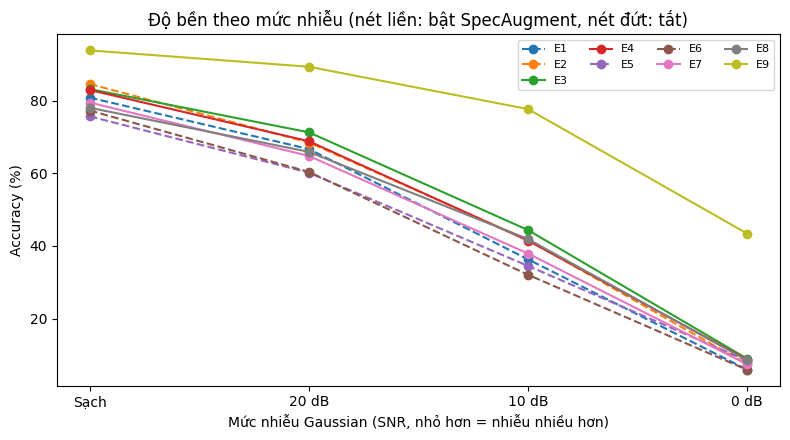

Mức giảm Accuracy từ dữ liệu sạch đến SNR 0 dB (điểm %):
  E1 (tắt): -74.85 | E3 (bật): -74.20
  E2 (tắt): -77.10 | E4 (bật): -74.20
  E5 (tắt): -67.25 | E7 (bật): -72.05
  E6 (tắt): -71.35 | E8 (bật): -69.50


In [7]:
COND_ORDER = ["Sạch", "20 dB", "10 dB", "0 dB"]
rob_acc = rob.groupby(["exp", "condition"])["acc"].mean().unstack()[COND_ORDER]
rob_acc = rob_acc.reindex([e for e in ordered if e in rob_acc.index])
display((rob_acc * 100).round(2).rename_axis("Accuracy (%) theo mức nhiễu"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for e in rob_acc.index:
    style = "-" if EXPERIMENTS[e]["specaug"] else "--"
    ax.plot(COND_ORDER, rob_acc.loc[e] * 100, style, marker="o", label=e)
ax.set_ylabel("Accuracy (%)")
ax.set_xlabel("Mức nhiễu Gaussian (SNR, nhỏ hơn = nhiễu nhiều hơn)")
ax.set_title("Độ bền theo mức nhiễu (nét liền: bật SpecAugment, nét đứt: tắt)")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

print("Mức giảm Accuracy từ dữ liệu sạch đến SNR 0 dB (điểm %):")
for a, b in RQ_PAIRS["RQ3: bật so với tắt SpecAugment"]:
    if a in rob_acc.index and b in rob_acc.index:
        drop_a = (rob_acc.loc[a, "Sạch"] - rob_acc.loc[a, "0 dB"]) * 100
        drop_b = (rob_acc.loc[b, "Sạch"] - rob_acc.loc[b, "0 dB"]) * 100
        print(f"  {a} (tắt): -{drop_a:.2f} | {b} (bật): -{drop_b:.2f}")

### 8.6. Confusion matrix và các cặp lớp hay nhầm

Cấu hình dùng để phân tích: E9


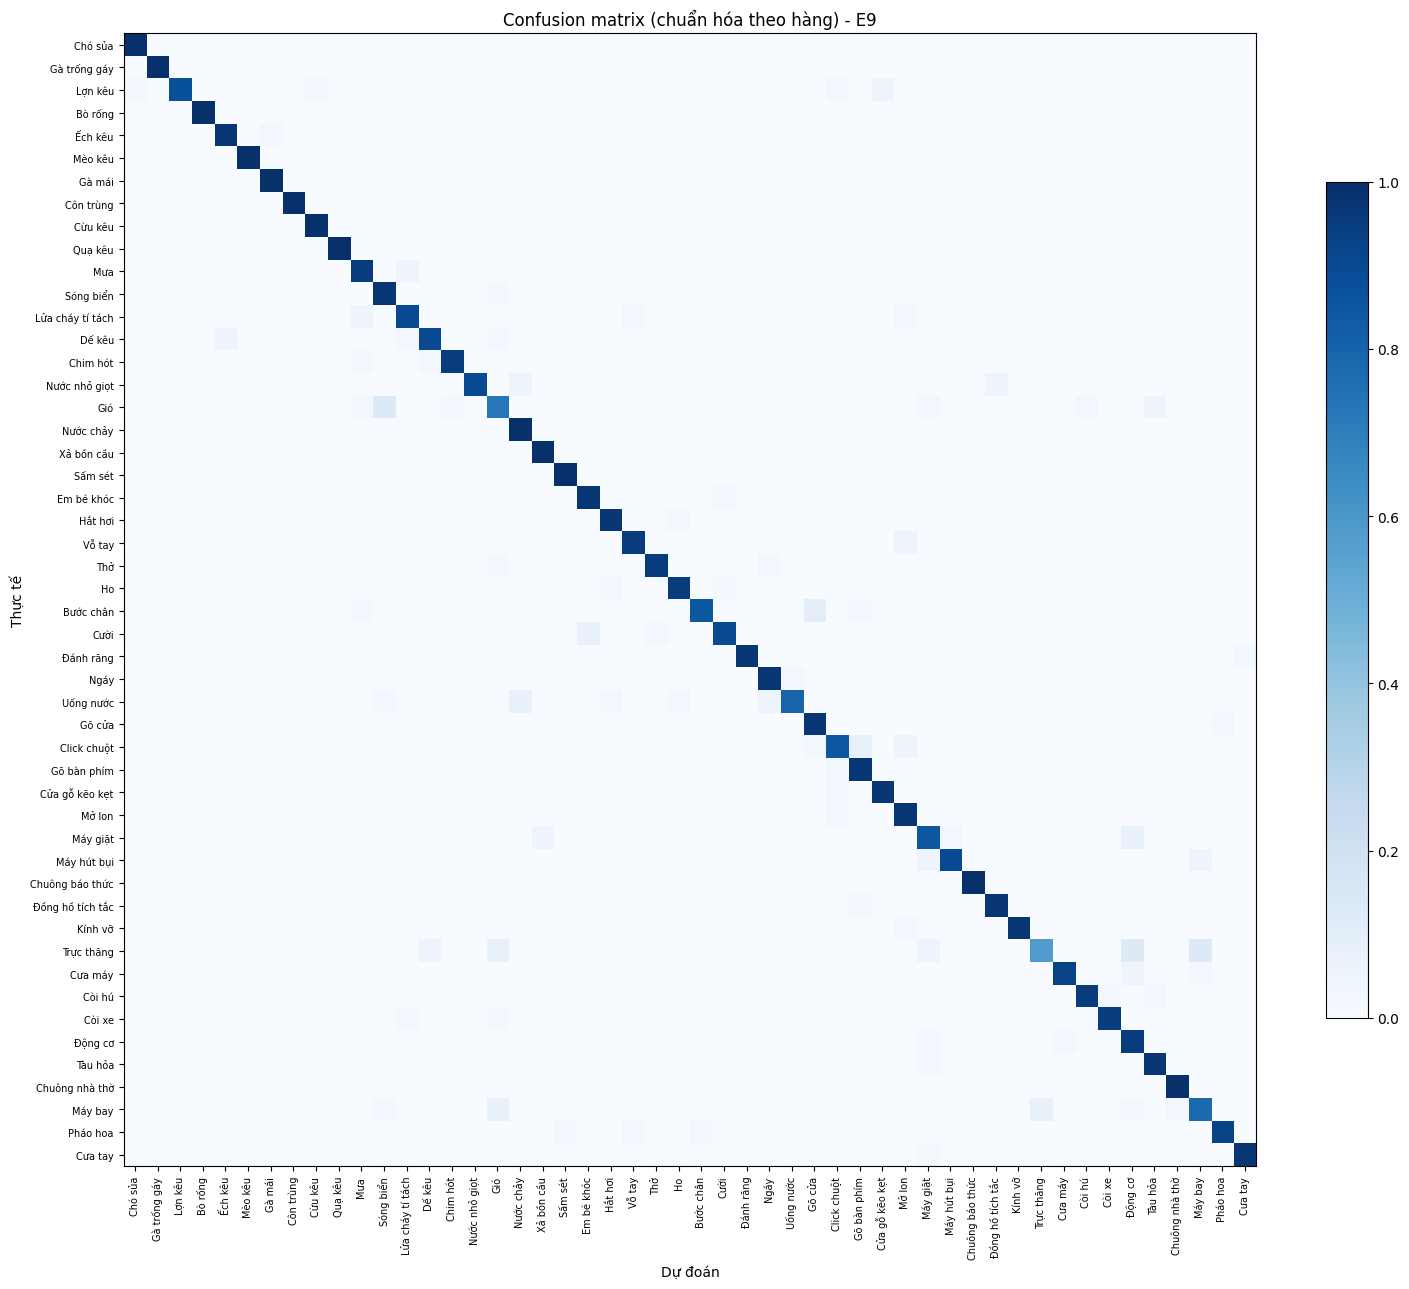


10 cặp hay bị nhầm nhất (thực tế → dự đoán):
  Trực thăng           → Động cơ             : 5 lần
  Trực thăng           → Máy bay             : 5 lần
  Gió                  → Sóng biển           : 5 lần
  Bước chân            → Gõ cửa              : 4 lần
  Máy giặt             → Động cơ             : 3 lần
  Trực thăng           → Gió                 : 3 lần
  Máy bay              → Trực thăng          : 3 lần
  Máy bay              → Gió                 : 3 lần
  Click chuột          → Gõ bàn phím         : 3 lần
  Cười                 → Em bé khóc          : 3 lần

Độ chính xác khi chỉ xét 5 nhóm lớn:
  Động vật              : 99.2%
  Thiên nhiên và nước   : 97.5%
  Âm thanh con người    : 96.5%
  Âm thanh trong nhà    : 98.0%
  Tiếng ồn đô thị       : 95.2%

5 lớp có F1 thấp nhất: Trực thăng (0.70), Gió (0.73), Máy bay (0.78), Máy giặt (0.83), Động cơ (0.85)


In [8]:
CM_EXP = None
best_exp = CM_EXP or summary["f1_mean"].idxmax()
print("Cấu hình dùng để phân tích:", best_exp)

yt = np.concatenate([np.load(RESULT_DIR / f"pred_{best_exp}_fold{f}.npy")[0] for f in FOLDS_DONE])
yp = np.concatenate([np.load(RESULT_DIR / f"pred_{best_exp}_fold{f}.npy")[1] for f in FOLDS_DONE])

labels = list(range(CFG["NUM_CLASSES"]))
cm = confusion_matrix(yt, yp, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(labels)
ax.set_yticks(labels)
ax.set_xticklabels(VI_LIST, rotation=90, fontsize=7)
ax.set_yticklabels(VI_LIST, fontsize=7)
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Thực tế")
ax.set_title(f"Confusion matrix (chuẩn hóa theo hàng) - {best_exp}")
plt.colorbar(im, fraction=0.03)
plt.tight_layout()
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:10], off.shape))[0]
print("\n10 cặp hay bị nhầm nhất (thực tế → dự đoán):")
for t, p in top:
    print(f"  {VI_LIST[t]:20s} → {VI_LIST[p]:20s}: {off[t, p]} lần")

print("\nĐộ chính xác khi chỉ xét 5 nhóm lớn:")
for g, name in enumerate(GROUP_NAMES):
    mask = (yt // 10) == g
    print(f"  {name:22s}: {np.mean((yp[mask] // 10) == g) * 100:.1f}%")

per_class_f1 = f1_score(yt, yp, average=None, labels=labels, zero_division=0)
worst = np.argsort(per_class_f1)[:5]
print("\n5 lớp có F1 thấp nhất:", ", ".join(f"{VI_LIST[i]} ({per_class_f1[i]:.2f})" for i in worst))

### 8.7. Precision, Recall và F1 theo lớp

10 lớp có F1 thấp nhất:


,Lớp,Nhóm,Precision,Recall,F1
0,Trực thăng,Tiếng ồn đô thị,0.885,0.575,0.697
1,Gió,Thiên nhiên và nước,0.744,0.725,0.734
2,Máy bay,Tiếng ồn đô thị,0.795,0.775,0.785
3,Máy giặt,Âm thanh trong nhà,0.810,0.850,0.829
4,Động cơ,Tiếng ồn đô thị,0.776,0.950,0.854
5,Click chuột,Âm thanh trong nhà,0.895,0.850,0.872
6,Uống nước,Âm thanh con người,0.970,0.800,0.877
7,Lửa cháy tí tách,Thiên nhiên và nước,0.900,0.900,0.900
8,Bước chân,Âm thanh con người,0.971,0.850,0.907
9,Sóng biển,Thiên nhiên và nước,0.848,0.975,0.907


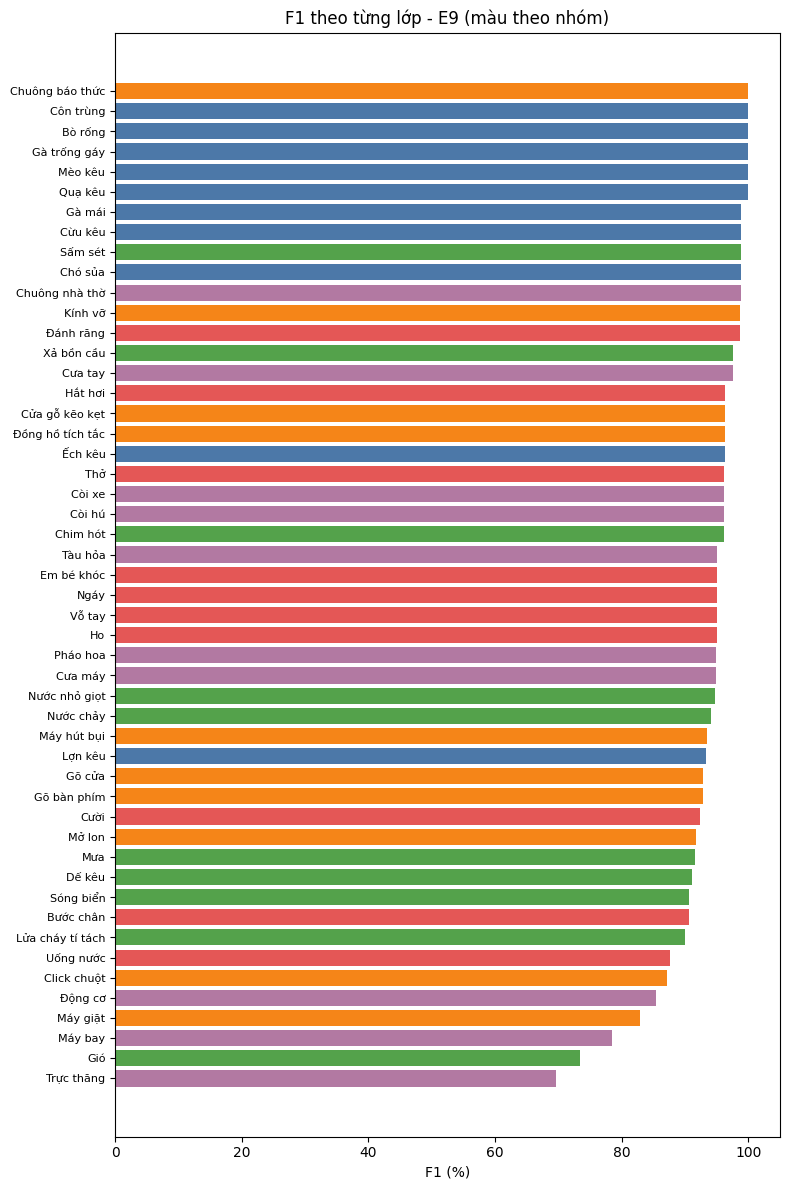

In [9]:
prec, rec, f1c, _ = precision_recall_fscore_support(yt, yp, labels=labels, zero_division=0)
per_class = pd.DataFrame({
    "Lớp": VI_LIST,
    "Nhóm": [GROUP_NAMES[i // 10] for i in labels],
    "Precision": prec, "Recall": rec, "F1": f1c,
}).sort_values("F1").reset_index(drop=True)
per_class.to_csv(RESULT_DIR / f"per_class_{best_exp}.csv", index=False)
print("10 lớp có F1 thấp nhất:")
display(per_class.head(10).round(3))

order = per_class.sort_values("F1")
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order["Lớp"], order["F1"] * 100,
        color=[GROUP_COLORS[GROUP_NAMES.index(g)] for g in order["Nhóm"]])
ax.set_xlabel("F1 (%)")
ax.set_title(f"F1 theo từng lớp - {best_exp} (màu theo nhóm)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

### 8.8. Các mẫu bị dự đoán sai

Fold 1 (E9): sai 24/400 mẫu (6.0%)


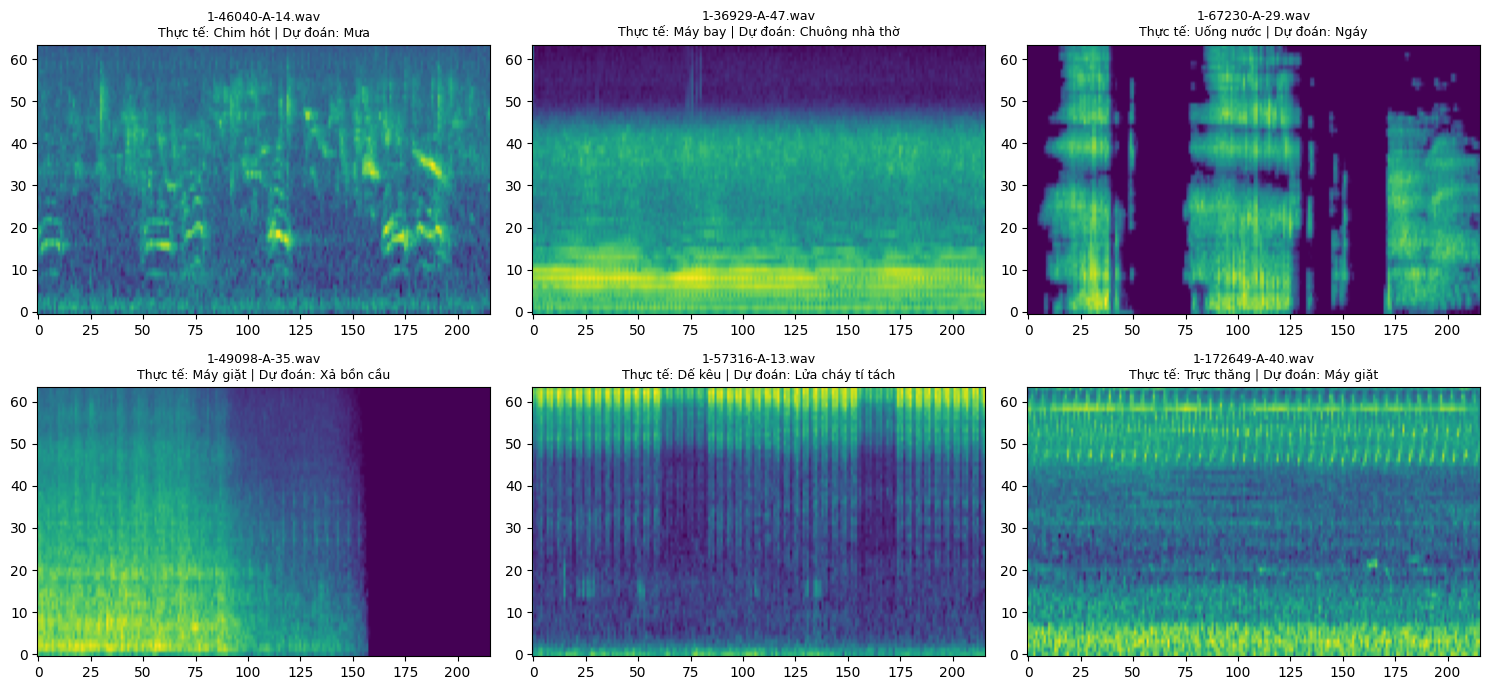

1-46040-A-14.wav | thực tế: Chim hót | dự đoán: Mưa


1-36929-A-47.wav | thực tế: Máy bay | dự đoán: Chuông nhà thờ


1-67230-A-29.wav | thực tế: Uống nước | dự đoán: Ngáy


In [10]:
EX_FOLD = FOLDS_DONE[0]
_, _, te_idx = get_split(EX_FOLD)
yt_f, yp_f = np.load(RESULT_DIR / f"pred_{best_exp}_fold{EX_FOLD}.npy")
assert (y[te_idx].numpy() == yt_f).all()
wrong = np.where(yt_f != yp_f)[0]
print(f"Fold {EX_FOLD} ({best_exp}): sai {len(wrong)}/{len(yt_f)} mẫu ({len(wrong) / len(yt_f):.1%})")

if len(wrong) > 0:
    from IPython.display import Audio
    pick = np.random.RandomState(0).choice(wrong, size=min(6, len(wrong)), replace=False)
    fe = LogMel(EXPERIMENTS[best_exp]["n_mels"]).to(DEVICE)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, k in zip(axes.ravel(), pick):
        i = te_idx[k]
        spec = fe(X[i:i + 1].to(DEVICE))[0, 0].cpu().numpy()
        ax.imshow(spec, origin="lower", aspect="auto")
        ax.set_title(f"{meta['filename'][i]}\nThực tế: {VI_LIST[yt_f[k]]} | Dự đoán: {VI_LIST[yp_f[k]]}",
                     fontsize=9)
    for ax in axes.ravel()[len(pick):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    for k in pick[:3]:
        i = te_idx[k]
        print(f"{meta['filename'][i]} | thực tế: {VI_LIST[yt_f[k]]} | dự đoán: {VI_LIST[yp_f[k]]}")
        display(Audio(X[i].numpy(), rate=SR))